# Smartphone Usage Risk Classification — Full Colab Notebook

**Dataset:** `Smartphone_Usage_And_Addiction_Analysis.csv'

## 1. Install/import libraries

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 2. Upload the CSV

In [ ]:
uploaded = files.upload()
csv_file = next(name for name in uploaded.keys() if name.lower().endswith(".csv"))
df = pd.read_csv(csv_file)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Saving Smartphone_Usage_And_Addiction_Analysis.csv to Smartphone_Usage_And_Addiction_Analysis.csv
Dataset shape: (7500, 16)


,transaction_id,user_id,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,academic_work_impact,addiction_level,addicted_label
0,TXN00001,U00001,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,NaN,0
1,TXN00002,U00002,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,NaN,0
2,TXN00003,U00003,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,Mild,0
3,TXN00004,U00004,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,Moderate,1
4,TXN00005,U00005,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,Severe,1



Column names:
['transaction_id', 'user_id', 'age', 'gender', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time', 'stress_level', 'academic_work_impact', 'addiction_level', 'addicted_label']


## 3.clean the dataset

In [ ]:
# Remove accidental spaces from column names and duplicate rows.
df.columns = df.columns.str.strip()
df = df.drop_duplicates().copy()

# Convert expected numeric columns to numbers; invalid values become missing.
numeric_cols = [
    "age", "daily_screen_time_hours", "social_media_hours",
    "gaming_hours", "work_study_hours", "sleep_hours",
    "notifications_per_day"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values before model imputation:")
display(df.isnull().sum().to_frame("missing_values"))
print("Shape after duplicate removal:", df.shape)

Missing values before model imputation:


,missing_values
transaction_id,0
user_id,0
age,0
gender,0
daily_screen_time_hours,0
social_media_hours,0
gaming_hours,0
work_study_hours,0
sleep_hours,0
notifications_per_day,0


Shape after duplicate removal: (7500, 16)


## 4. Exploratory Data Analysis (EDA)

,count,mean,std,min,25%,50%,75%,max
age,7500.0,26.568800,5.197108,18.0,22.00,27.000,31.00,35.0
daily_screen_time_hours,7500.0,7.499912,2.609188,3.0,5.22,7.525,9.81,12.0
social_media_hours,7500.0,3.273484,1.585342,0.5,1.91,3.270,4.63,6.0
gaming_hours,7500.0,2.014183,1.146039,0.0,1.02,2.040,2.99,4.0
work_study_hours,7500.0,3.242420,1.600765,0.5,1.85,3.230,4.64,6.0
sleep_hours,7500.0,6.737561,1.283605,4.5,5.63,6.720,7.84,9.0
notifications_per_day,7500.0,134.257333,66.586883,20.0,76.00,134.000,191.00,250.0


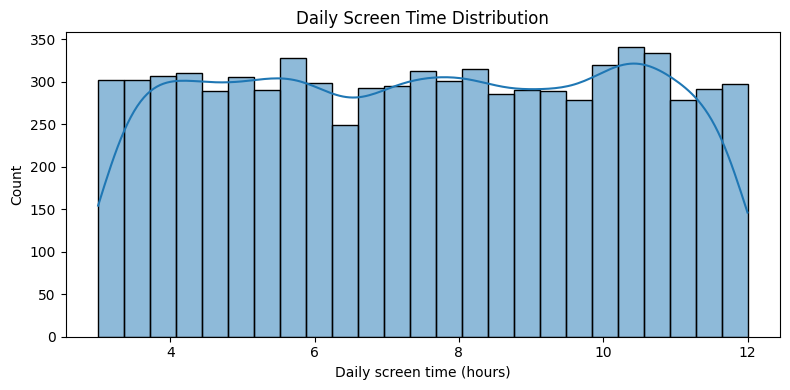

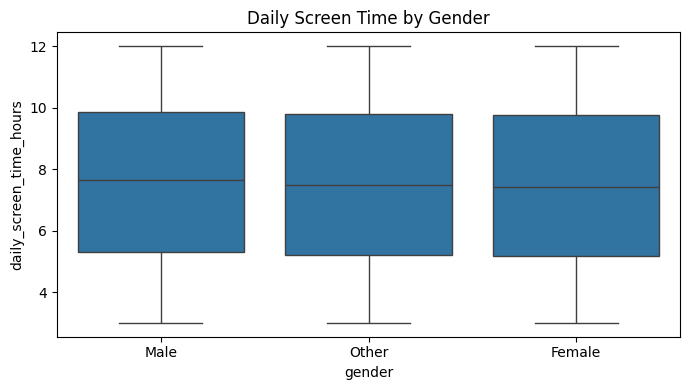

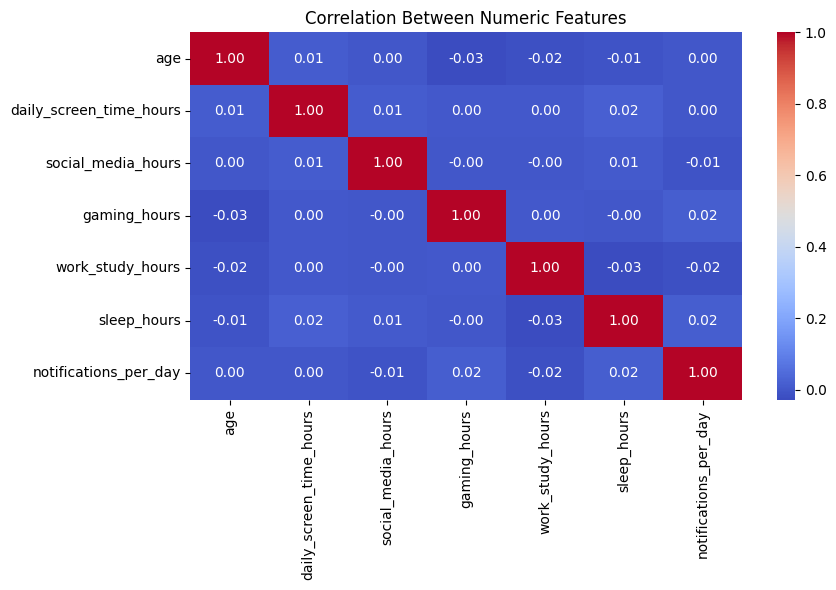

In [ ]:
# Summary statistics for numeric columns.
display(df[numeric_cols].describe().T)

# Distribution of daily screen time.
plt.figure(figsize=(8, 4))
sns.histplot(df["daily_screen_time_hours"].dropna(), bins=25, kde=True)
plt.title("Daily Screen Time Distribution")
plt.xlabel("Daily screen time (hours)")
plt.tight_layout()
plt.show()

# Compare screen time across gender, if gender exists.
if "gender" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="gender", y="daily_screen_time_hours")
    plt.title("Daily Screen Time by Gender")
    plt.tight_layout()
    plt.show()

# Correlation between numeric variables.
plt.figure(figsize=(9, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

##5.confidence interval

In [ ]:
import scipy.stats as stats
import numpy as np

screen_time = df['daily_screen_time_hours'].dropna()
n = len(screen_time)
mean = screen_time.mean()
std = screen_time.std()
sem = std / np.sqrt(n)

confidence_level = 0.95
z_critical = stats.norm.ppf((1 + confidence_level) / 2)  # 1.96 for 95%
margin_of_error = z_critical * sem

ci_lower = mean - margin_of_error
ci_upper = mean + margin_of_error

print("=" * 55)
print("95% CONFIDENCE INTERVAL ESTIMATION")
print("=" * 55)
print(f"Sample Size (n)       : {n}")
print(f"Sample Mean (x̄)       : {mean:.4f} hours")
print(f"Standard Error (SEM)  : {sem:.4f}")
print(f"Margin of Error       : ±{margin_of_error:.4f}")
print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}] hours")
print("=" * 55)
print(f"Interpretation: We are 95% confident that the true population mean")
print(f"daily screen time lies between {ci_lower:.2f} and {ci_upper:.2f} hours.")

95% CONFIDENCE INTERVAL ESTIMATION
Sample Size (n)       : 7500
Sample Mean (x̄)       : 7.4999 hours
Standard Error (SEM)  : 0.0301
Margin of Error       : ±0.0591
95% Confidence Interval: [7.4409, 7.5590] hours
Interpretation: We are 95% confident that the true population mean
daily screen time lies between 7.44 and 7.56 hours.


##6.Sample Z-test

In [ ]:
mu_hypothesized = 6.0
z_stat = (mean - mu_hypothesized) / (std / np.sqrt(n))
p_value_z = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print("=" * 55)
print("ONE-SAMPLE Z-TEST")
print("=" * 55)
print(f"Hypothesized Mean (μ0): {mu_hypothesized} hours")
print(f"Sample Mean (x̄)       : {mean:.4f} hours")
print(f"Z-Statistic           : {z_stat:.4f}")
print(f"P-Value               : {p_value_z:.8e}")
print("-" * 55)

if p_value_z < 0.05:
    print("Decision: REJECT H0")
    print("Conclusion: Significant difference from 6.0 hours (p < 0.05).")
else:
    print("Decision: FAIL TO REJECT H0")

ONE-SAMPLE Z-TEST
Hypothesized Mean (μ0): 6.0 hours
Sample Mean (x̄)       : 7.4999 hours
Z-Statistic           : 49.7842
P-Value               : 0.00000000e+00
-------------------------------------------------------
Decision: REJECT H0
Conclusion: Significant difference from 6.0 hours (p < 0.05).


##7.sample t-test (small sample size)

In [ ]:
small_sample = df['sleep_hours'].dropna().sample(n=25, random_state=42)

mu_sleep = 8.0
t_stat, p_val_two_tail = stats.ttest_1samp(small_sample, popmean=mu_sleep)
p_val_one_tail = p_val_two_tail / 2 if t_stat < 0 else 1 - (p_val_two_tail / 2)

print("=" * 55)
print("ONE-SAMPLE T-TEST (n=25)")
print("=" * 55)
print(f"Sample Mean Sleep  : {small_sample.mean():.4f} hours")
print(f"Target Mean (μ0)   : {mu_sleep} hours")
print(f"T-Statistic        : {t_stat:.4f}")
print(f"One-tailed P-Value : {p_val_one_tail:.6f}")
print("-" * 55)

if p_val_one_tail < 0.05:
    print("Decision: REJECT H0")
    print("Conclusion: Sleep hours are significantly lower than 8 hours.")
else:
    print("Decision: FAIL TO REJECT H0")

ONE-SAMPLE T-TEST (n=25)
Sample Mean Sleep  : 6.6912 hours
Target Mean (μ0)   : 8.0 hours
T-Statistic        : -4.7524
One-tailed P-Value : 0.000039
-------------------------------------------------------
Decision: REJECT H0
Conclusion: Sleep hours are significantly lower than 8 hours.


##8.chi-square of independent square

academic_work_impact,No,Yes
stress_level,,
High,1256,1304
Low,1256,1247
Medium,1241,1196


Chi-Square Statistic (χ²): 1.7585
Degrees of Freedom (df)  : 2
P-Value                  : 0.415094
Cramér's V (Effect Size) : 0.0153
-------------------------------------------------------
Decision: FAIL TO REJECT H0 (No significant association).


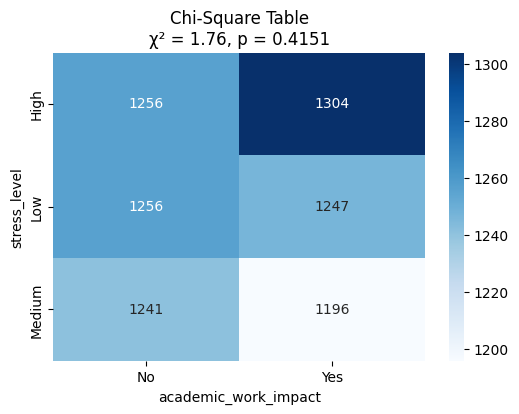

In [ ]:
contingency_table = pd.crosstab(df['stress_level'], df['academic_work_impact'])
display(contingency_table)

chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)
total_obs = contingency_table.values.sum()
cramers_v = np.sqrt(chi2_stat / (total_obs * (min(contingency_table.shape) - 1)))

print("=" * 55)
print(f"Chi-Square Statistic (χ²): {chi2_stat:.4f}")
print(f"Degrees of Freedom (df)  : {dof}")
print(f"P-Value                  : {p_val_chi2:.6f}")
print(f"Cramér's V (Effect Size) : {cramers_v:.4f}")
print("-" * 55)

if p_val_chi2 < 0.05:
    print("Decision: REJECT H0 (Significant association exists).")
else:
    print("Decision: FAIL TO REJECT H0 (No significant association).")

plt.figure(figsize=(6, 4))
sns.heatmap(contingency_table, annot=True, fmt='d', cmap='Blues')
plt.title(f"Chi-Square Table\nχ² = {chi2_stat:.2f}, p = {p_val_chi2:.4f}")
plt.show()

##9.One-Way ANOVA

ONE-WAY ANOVA TEST
Mild Mean     : 5.535 hrs
Moderate Mean : 8.351 hrs
Severe Mean   : 8.605 hrs
F-Statistic   : 962.5263
P-Value       : 0.00000000e+00
-------------------------------------------------------
Decision: REJECT H0 (Statistically significant difference across classes).


/tmp/ipykernel_5066/718710980.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.dropna(subset=['addiction_level']),


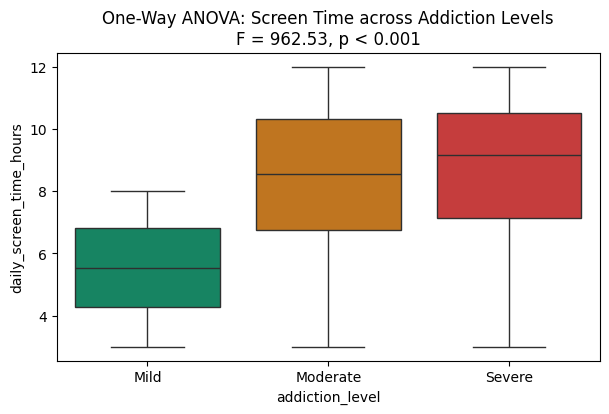

In [ ]:
mild_st = df[df['addiction_level'] == 'Mild']['daily_screen_time_hours'].dropna()
mod_st  = df[df['addiction_level'] == 'Moderate']['daily_screen_time_hours'].dropna()
sev_st  = df[df['addiction_level'] == 'Severe']['daily_screen_time_hours'].dropna()

f_stat, p_val_anova = stats.f_oneway(mild_st, mod_st, sev_st)

print("=" * 55)
print("ONE-WAY ANOVA TEST")
print("=" * 55)
print(f"Mild Mean     : {mild_st.mean():.3f} hrs")
print(f"Moderate Mean : {mod_st.mean():.3f} hrs")
print(f"Severe Mean   : {sev_st.mean():.3f} hrs")
print(f"F-Statistic   : {f_stat:.4f}")
print(f"P-Value       : {p_val_anova:.8e}")
print("-" * 55)

if p_val_anova < 0.05:
    print("Decision: REJECT H0 (Statistically significant difference across classes).")
else:
    print("Decision: FAIL TO REJECT H0")

plt.figure(figsize=(7, 4))
sns.boxplot(data=df.dropna(subset=['addiction_level']),
            x='addiction_level', y='daily_screen_time_hours',
            order=['Mild', 'Moderate', 'Severe'],
            palette=['#059669', '#d97706', '#dc2626'])
plt.title(f"One-Way ANOVA: Screen Time across Addiction Levels\nF = {f_stat:.2f}, p < 0.001")
plt.show()

In [ ]:
# 1. Define Numeric and Categorical Features
numeric_features = [
    'age', 'daily_screen_time_hours', 'social_media_hours',
    'gaming_hours', 'work_study_hours', 'sleep_hours',
    'notifications_per_day'
]
categorical_features = ['gender']

# Ensure the demo target and train/test variables are created before fitting
# (If not already run below, we can create them here to make this cell self-contained)
if 'usage_risk_category_demo' not in df.columns:
    def make_demo_target(row):
        social_and_gaming = row["social_media_hours"] + row["gaming_hours"]
        if (row["daily_screen_time_hours"] >= 8) or (social_and_gaming >= 5 and row["sleep_hours"] < 6):
            return "Elevated"
        elif row["daily_screen_time_hours"] >= 5 or social_and_gaming >= 3 or row["sleep_hours"] < 7:
            return "Moderate"
        else:
            return "Low"
    df["usage_risk_category_demo"] = df.apply(make_demo_target, axis=1)

X = df[numeric_features + categorical_features].copy()
y = df["usage_risk_category_demo"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# 2. Numeric Transformer: Imputation + StandardScaler
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 3. Categorical Transformer: Imputation + OneHotEncoder
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 4. Combine into Preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# 5. Build Final Machine Learning Pipeline with Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=300, max_depth=16, class_weight='balanced', random_state=42))
])

# 6. Fit Model
rf_pipeline.fit(X_train, y_train)

# 7. Evaluate
y_pred = rf_pipeline.predict(X_test)
print("Model trained successfully with StandardScaler!")
print(classification_report(y_test, y_pred))

Model trained successfully with StandardScaler!
              precision    recall  f1-score   support

    Elevated       1.00      0.99      0.99       826
         Low       0.94      0.80      0.86        20
    Moderate       0.98      0.99      0.99       654

    accuracy                           0.99      1500
   macro avg       0.97      0.93      0.95      1500
weighted avg       0.99      0.99      0.99      1500



## 8. Create a demonstration target label

Demo target distribution:


,count
usage_risk_category_demo,
Elevated,4130
Moderate,3272
Low,98


,percentage
usage_risk_category_demo,
Elevated,55.07
Moderate,43.63
Low,1.31


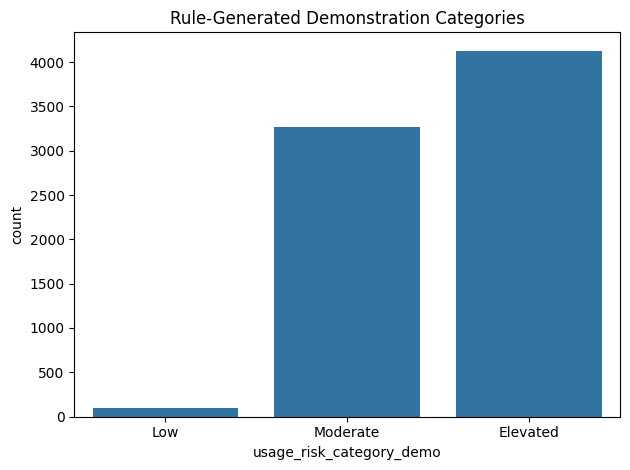

In [ ]:
def make_demo_target(row):
    social_and_gaming = row["social_media_hours"] + row["gaming_hours"]

    if (row["daily_screen_time_hours"] >= 8) or (
        social_and_gaming >= 5 and row["sleep_hours"] < 6
    ):
        return "Elevated"
    elif (
        row["daily_screen_time_hours"] >= 5
        or social_and_gaming >= 3
        or row["sleep_hours"] < 7
    ):
        return "Moderate"
    else:
        return "Low"

df["usage_risk_category_demo"] = df.apply(make_demo_target, axis=1)

print("Demo target distribution:")
display(df["usage_risk_category_demo"].value_counts().to_frame("count"))
display((df["usage_risk_category_demo"].value_counts(normalize=True) * 100)
        .round(2).to_frame("percentage"))

sns.countplot(data=df, x="usage_risk_category_demo",
              order=["Low", "Moderate", "Elevated"])
plt.title("Rule-Generated Demonstration Categories")
plt.tight_layout()
plt.show()

## 6. Choose features and split the data

In [ ]:
# IDs are not used as predictive features.
feature_cols = [
    "age", "gender", "daily_screen_time_hours", "social_media_hours",
    "gaming_hours", "work_study_hours", "sleep_hours",
    "notifications_per_day"
]
target_col = "usage_risk_category_demo"

X = df[feature_cols].copy()
y = df[target_col].copy()

numeric_features = [
    "age", "daily_screen_time_hours", "social_media_hours",
    "gaming_hours", "work_study_hours", "sleep_hours",
    "notifications_per_day"
]
categorical_features = ["gender"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 6000
Testing rows: 1500


## 7. Preprocess and train multiple classification algorithms

In [ ]:
# Numeric values: fill missing values with median, then scale.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical values: fill missing values with most common value, then one-hot encode.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, class_weight="balanced", max_depth=8
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE,
        class_weight="balanced", max_depth=12
    )
}

trained_models = {}
results = []

for model_name, classifier in models.items():
    # Pipeline keeps preprocessing and model together, preventing mismatch at prediction time.
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", classifier)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    trained_models[model_name] = pipeline
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision_macro": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, predictions, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(
    by=["F1_macro", "Accuracy"], ascending=False
).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Decision Tree,0.9893,0.9616,0.9766,0.9689
1,Random Forest,0.9887,0.9559,0.9273,0.9408
2,Logistic Regression,0.8360,0.6881,0.8879,0.7383


## 8. Evaluate the selected model

Selected model: Decision Tree

Classification report:
              precision    recall  f1-score   support

    Elevated       1.00      0.99      0.99       826
         Low       0.90      0.95      0.93        20
    Moderate       0.98      0.99      0.99       654

    accuracy                           0.99      1500
   macro avg       0.96      0.98      0.97      1500
weighted avg       0.99      0.99      0.99      1500



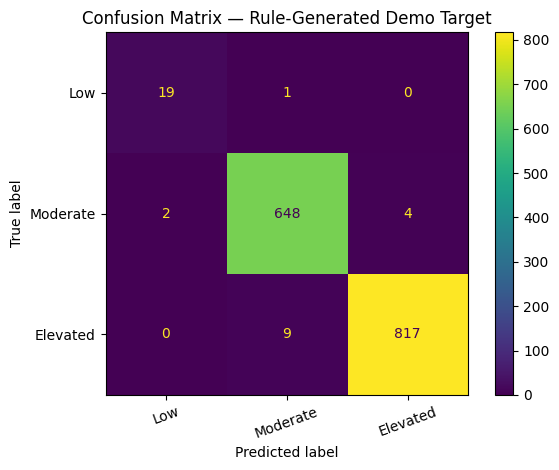

Reminder: these metrics measure agreement with the rule-generated label,
not real-world addiction detection accuracy.


In [ ]:
# Select the model using macro F1 first, then accuracy.
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=["Low", "Moderate", "Elevated"], xticks_rotation=20
)
plt.title("Confusion Matrix — Rule-Generated Demo Target")
plt.tight_layout()
plt.show()

print("Reminder: these metrics measure agreement with the rule-generated label,")
print("not real-world addiction detection accuracy.")

## 9. Save all `.pkl` files

In [ ]:
# Save the full preprocessing + classifier pipeline as one file.
with open("smartphone_usage_risk_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

# Save the exact feature order expected by the model.
with open("smartphone_usage_feature_columns.pkl", "wb") as file:
    pickle.dump(feature_cols, file)

# Save possible output categories.
with open("smartphone_usage_target_classes.pkl", "wb") as file:
    pickle.dump(sorted(y.unique().tolist()), file)

# Save metadata documenting the model and its limitation.
metadata = {
    "best_model_name": best_model_name,
    "target_column": target_col,
    "feature_columns": feature_cols,
    "target_is_rule_based_demo": True,
    "target_rules": {
        "Elevated": "daily_screen_time_hours >= 8 OR (social_media_hours + gaming_hours >= 5 AND sleep_hours < 6)",
        "Moderate": "not Elevated AND (daily_screen_time_hours >= 5 OR social_media_hours + gaming_hours >= 3 OR sleep_hours < 7)",
        "Low": "otherwise"
    },
    "warning": "Rule-generated usage-risk category; not a validated addiction diagnosis."
}
with open("smartphone_usage_model_metadata.pkl", "wb") as file:
    pickle.dump(metadata, file)

print("Saved:")
print("- smartphone_usage_risk_model.pkl")
print("- smartphone_usage_feature_columns.pkl")
print("- smartphone_usage_target_classes.pkl")
print("- smartphone_usage_model_metadata.pkl")

Saved:
- smartphone_usage_risk_model.pkl
- smartphone_usage_feature_columns.pkl
- smartphone_usage_target_classes.pkl
- smartphone_usage_model_metadata.pkl


## 10. Test a sample prediction

In [ ]:
# Example only. Change these values to test another hypothetical user.
sample_user = pd.DataFrame([{
    "age": 21,
    "gender": "Female",
    "daily_screen_time_hours": 6.5,
    "social_media_hours": 2.5,
    "gaming_hours": 1.0,
    "work_study_hours": 4.0,
    "sleep_hours": 6.5,
    "notifications_per_day": 80
}])[feature_cols]

predicted_category = best_model.predict(sample_user)[0]
print("Predicted demonstration usage-risk category:", predicted_category)
print("This is not a medical diagnosis.")

Predicted demonstration usage-risk category: Moderate
This is not a medical diagnosis.


## 11. Download the model files

In [ ]:
# Download the artifacts individually from Colab.
files.download("smartphone_usage_risk_model.pkl")
files.download("smartphone_usage_feature_columns.pkl")
files.download("smartphone_usage_target_classes.pkl")
files.download("smartphone_usage_model_metadata.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Download all generated PKL files together in one ZIP.
# Run this cell AFTER the model-saving cell above.
import zipfile
from google.colab import files

pkl_files = [
    "smartphone_usage_risk_model.pkl",
    "smartphone_usage_feature_columns.pkl",
    "smartphone_usage_target_classes.pkl",
    "smartphone_usage_model_metadata.pkl"
]

with zipfile.ZipFile("Smartphone_Usage_PKL_Files.zip", "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file_name in pkl_files:
        zip_file.write(file_name)

files.download("Smartphone_Usage_PKL_Files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>